<a href="https://colab.research.google.com/github/gttfg/Algorithm-Practice/blob/main/Ironman.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [91]:
%%writefile my_utils.py

import numpy as np
from matplotlib.patches import Polygon

MAIN_COLOR = '#E63946'
SECOND_COLOR = '#F4C430'
POWER_COLOR = '#8E44AD'
SPACE_COLOR = '#287FB5'
TIME_COLOR = '#2EAD5B'
SOUL_COLOR = '#F28C28'
REALITY_COLOR = '#800020'


# 2차원 변환 함수

def translate(p, dx, dy):
    """이동 변환"""
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([
        [1.0, 0.0, dx],
        [0.0, 1.0, dy],
        [0.0, 0.0, 1.0]
    ])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


def rotate(p, theta):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([
        [np.cos(theta), -np.sin(theta), 0.0],
        [np.sin(theta),  np.cos(theta), 0.0],
        [0.0,            0.0,           1.0]
    ])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


def scale(p, sx, sy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([
        [sx,  0.0, 0.0],
        [0.0, sy,  0.0],
        [0.0, 0.0, 1.0]
    ])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


def shear_x(p, sx):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([
        [1.0, sx,  0.0],
        [0.0, 1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


def shear_y(p, sy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([
        [1.0, 0.0, 0.0],
        [sy,  1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

# 기본 그리기 함수

def draw_rectangle(ax, points, facecolor=MAIN_COLOR, edgecolor=MAIN_COLOR):
    polygon = Polygon(
        points,
        closed=True,
        facecolor=facecolor,
        edgecolor=edgecolor
    )
    ax.add_patch(polygon)


def center_rectangle(points, LEN):
    return [translate(p, -LEN / 2, -LEN / 2) for p in points]


def make_base_rectangle(LEN):
    p1 = np.array([0.0, 0.0])
    p2 = np.array([LEN, 0.0])
    p3 = np.array([LEN, LEN])
    p4 = np.array([0.0, LEN])
    return [p1, p2, p3, p4]


def make_part(points, LEN, sx, sy, theta=0.0, dx=0.0, dy=0.0, shx=0.0):
    q = center_rectangle(points, LEN)
    q = [scale(p, sx, sy) for p in q]
    q = [shear_x(p, shx) for p in q]
    q = [rotate(p, theta) for p in q]
    q = [translate(p, dx, dy) for p in q]
    return q

# 로봇 손 구성 요소

def draw_forearm(ax, points, LEN):
    lower = make_part(points, LEN, 3.6, 3.0, dx=0, dy=-760)
    draw_rectangle(ax, lower)

    upper = make_part(points, LEN, 3.2, 2.4, dx=0, dy=-480)
    draw_rectangle(ax, upper)

    joint = make_part(points, LEN, 3.4, 0.3, dx=0, dy=-610)
    draw_rectangle(ax, joint, SECOND_COLOR, SECOND_COLOR)


def draw_wrist(ax, points, LEN):
    band = make_part(points, LEN, 3.8, 0.6, dx=0, dy=-330)
    draw_rectangle(ax, band, SECOND_COLOR, SECOND_COLOR)


def draw_palm(ax, points, LEN):
    palm = make_part(points, LEN, 4.4, 3.8, dx=10, dy=-100, shx=0.05)
    draw_rectangle(ax, palm)

    knuckle_bar = make_part(points, LEN, 4.4, 0.4, dx=20, dy=95)
    draw_rectangle(ax, knuckle_bar, SECOND_COLOR, SECOND_COLOR)


def draw_finger(ax, points, LEN, x, base_y, len1, len2, tilt_deg):
    theta = np.deg2rad(tilt_deg)
    direction = np.array([-np.sin(theta), np.cos(theta)])
    base = np.array([x, base_y])

    c1 = base + direction * (len1 / 2)
    seg1 = make_part(points, LEN, 0.9, len1 / LEN, theta, c1[0], c1[1])
    draw_rectangle(ax, seg1)

    cj = base + direction * (len1 + 15)
    joint = make_part(points, LEN, 0.55, 0.55, theta + np.pi / 4, cj[0], cj[1])
    draw_rectangle(ax, joint, SECOND_COLOR, SECOND_COLOR)

    c2 = base + direction * (len1 + 30 + len2 / 2)
    seg2 = make_part(points, LEN, 0.8, len2 / LEN, theta, c2[0], c2[1])
    draw_rectangle(ax, seg2)


def draw_fingers(ax, points, LEN):
    fingers = [(-150, 120, 190, 150,  6),
               ( -40, 120, 230, 180,  2),
               (  75, 120, 220, 170, -2),
               ( 185, 120, 170, 130, -7)]

    for x, y, l1, l2, tilt in fingers:
        draw_finger(ax, points, LEN, x, y, l1, l2, tilt)


def draw_thumb(ax, points, LEN):
    draw_finger(ax, points, LEN, -170, -200, 240, 150, 42)

def draw_time(ax, points, LEN, x, base_y, len1, len2, tilt_deg):
    theta = np.deg2rad(tilt_deg)
    direction = np.array([-np.sin(theta), np.cos(theta)])
    base = np.array([x, base_y])


    c = base + direction * (len1 + 30 + len2 - 350)

    q = center_rectangle(points, LEN)
    q = [rotate(p, np.pi / 4) for p in q]
    q = [scale(p, 0.5, 0.8) for p in q]
    q = [rotate(p, theta) for p in q]
    q = [translate(p, c[0], c[1]) for p in q]
    draw_rectangle(ax, q, TIME_COLOR, TIME_COLOR)

def draw_space(ax, points, LEN):
    """스페이스스톤"""
    x, base_y = -40, 120
    len1, len2 = 230, 180
    tilt_deg = 2

    nail_sx, nail_sy = 0.5, 0.8
    back = 480

    theta = np.deg2rad(tilt_deg)
    direction = np.array([-np.sin(theta), np.cos(theta)])
    base = np.array([x, base_y])


    c = base + direction * (len1 + 30 + len2 - back)

    q = center_rectangle(points, LEN)
    q = [rotate(p, np.pi / 4) for p in q]
    q = [scale(p, nail_sx, nail_sy) for p in q]
    q = [rotate(p, theta) for p in q]
    q = [translate(p, c[0], c[1]) for p in q]
    draw_rectangle(ax, q, SPACE_COLOR, SPACE_COLOR)

def draw_power(ax, points, LEN):
    """파워스톤"""
    x, base_y = -150, 120
    len1, len2 = 190, 150
    tilt_deg = 6

    nail_sx, nail_sy = 0.5, 0.8
    back = 420

    theta = np.deg2rad(tilt_deg)
    direction = np.array([-np.sin(theta), np.cos(theta)])
    base = np.array([x, base_y])

    c = base + direction * (len1 + 30 + len2 - back)

    q = center_rectangle(points, LEN)
    q = [rotate(p, np.pi / 4) for p in q]
    q = [scale(p, nail_sx, nail_sy) for p in q]
    q = [rotate(p, theta) for p in q]
    q = [translate(p, c[0], c[1]) for p in q]
    draw_rectangle(ax, q, POWER_COLOR, POWER_COLOR)

def draw_reality(ax, points, LEN):
    """리얼리티스톤"""
    x, base_y = 75, 120
    len1, len2 = 220, 170
    tilt_deg = -2

    nail_sx, nail_sy = 0.5, 0.8
    back = 450

    theta = np.deg2rad(tilt_deg)
    direction = np.array([-np.sin(theta), np.cos(theta)])
    base = np.array([x, base_y])

    c = base + direction * (len1 + 30 + len2 - back)

    q = center_rectangle(points, LEN)
    q = [rotate(p, np.pi / 4) for p in q]
    q = [scale(p, nail_sx, nail_sy) for p in q]
    q = [rotate(p, theta) for p in q]
    q = [translate(p, c[0], c[1]) for p in q]
    draw_rectangle(ax, q, REALITY_COLOR, REALITY_COLOR)

def draw_soul(ax, points, LEN):
    """소울스톤"""
    x, base_y = 185, 120
    len1, len2 = 170, 130
    tilt_deg = -7

    nail_sx, nail_sy = 0.5, 0.8
    back = 380

    theta = np.deg2rad(tilt_deg)
    direction = np.array([-np.sin(theta), np.cos(theta)])
    base = np.array([x, base_y])


    c = base + direction * (len1 + 30 + len2 - back)

    q = center_rectangle(points, LEN)
    q = [rotate(p, np.pi / 4) for p in q]
    q = [scale(p, nail_sx, nail_sy) for p in q]
    q = [rotate(p, theta) for p in q]
    q = [translate(p, c[0], c[1]) for p in q]
    draw_rectangle(ax, q, SOUL_COLOR, SOUL_COLOR)

def draw_mind(ax, points, LEN):
    """마인드스톤"""
    x, base_y = -10, 120
    len1, len2 = 230, 180
    tilt_deg = 2

    nail_sx, nail_sy = 0.8, 1.2
    back = 650

    theta = np.deg2rad(tilt_deg)
    direction = np.array([-np.sin(theta), np.cos(theta)])
    base = np.array([x, base_y])


    c = base + direction * (len1 + 30 + len2 - back)

    q = center_rectangle(points, LEN)
    q = [rotate(p, np.pi / 4) for p in q]
    q = [scale(p, nail_sx, nail_sy) for p in q]
    q = [rotate(p, theta) for p in q]
    q = [translate(p, c[0], c[1]) for p in q]
    draw_rectangle(ax, q, SECOND_COLOR, SECOND_COLOR)

# 전체 물체

def draw_object(ax, LEN):

    points = make_base_rectangle(LEN)

    # 1. 팔뚝
    draw_forearm(ax, points, LEN)

    # 2. 손목
    draw_wrist(ax, points, LEN)

    # 3. 엄지 (손바닥 뒤에 깔리도록 먼저)
    draw_thumb(ax, points, LEN)

    # 4. 손바닥
    draw_palm(ax, points, LEN)

    # 5. 네 손가락
    draw_fingers(ax, points, LEN)

    # 6. 스톤
    draw_space(ax, points, LEN)
    draw_reality(ax, points, LEN)
    draw_power(ax, points, LEN)
    draw_soul(ax, points, LEN)
    draw_time(ax, points, LEN, -170, -200, 240, 150, 42)
    draw_mind(ax, points, LEN)

Overwriting my_utils.py


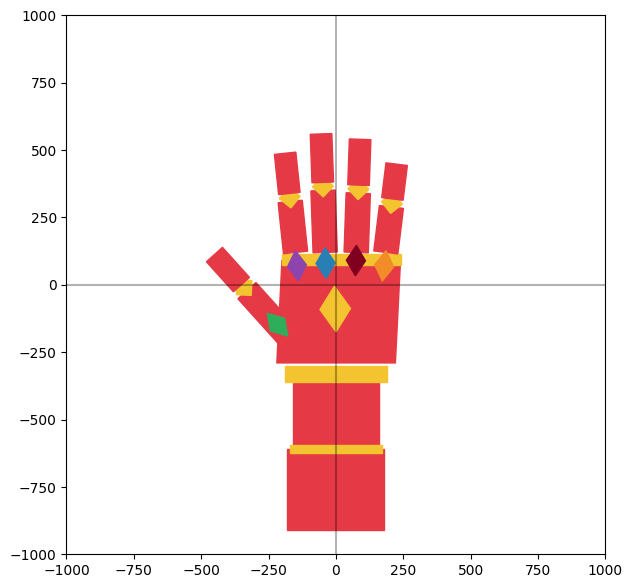

In [92]:
import matplotlib.pyplot as plt
import importlib
import my_utils

importlib.reload(my_utils)

INF = 1000
LEN = 100

def draw_axis(ax):
    ax.axhline(0, color='black', alpha=0.3)
    ax.axvline(0, color='black', alpha=0.3)

    ax.set_xlim(-INF, INF)
    ax.set_ylim(-INF, INF)
    ax.set_aspect('equal')

    ax.set_xticks(range(-1000, 1001, 250))
    ax.set_yticks(range(-1000, 1001, 250))

    ax.grid(False)

fig, ax = plt.subplots(figsize=(7, 7))

draw_axis(ax)

my_utils.draw_object(ax, LEN)

plt.show()